# mcTEC niches at k = 6

Neighbourhood composition within 50 µm of every mcTEC → fractions → log2 over a per-donor all-cell
background → PCA(10) → MiniBatchKMeans at **k = 6**. Pipeline unchanged from LM's
`morphoFM/00_mcTEC_niche.ipynb`; the k sweep that led to k = 6 is in `00_mcTEC_niche_VK.ipynb`.

**Why k = 6.** No k gives a stable partition (ARI between refits 0.42-0.45 for every k in 4…7, all
below the 0.5 "unstable" line, silhouette ~0.1) — the composition space is a gradient, so k is a
choice of resolution rather than a discovery. Given that, k = 6 costs nothing statistically: its
niches are the *least* redundant in the sweep (max pairwise profile r = 0.725 vs 0.744 at k = 4),
and it resolves the k = 4 adult bucket, which had the worst cross-donor consistency anywhere
(min donor r = 0.409). Section 8 re-runs those checks for k = 6 alone.

**Two cell-type resolutions.** The niches are defined on `taa_l2_comb`, as LM did — that is the
partition the sweep validated. `taa_l3_comb` (50 types) describes those same niches at finer
resolution; it does not redefine them.

**Two views of every niche.** The proportion of cells within the niche (what the neighbourhood *is*)
and the log2 enrichment over the tissue background (what makes it *different*). Thymus is mostly
thymocytes, so proportions are dominated by T_DP everywhere and enrichment is what separates the
niches — both are shown for each panel, on a shared clustering so they line up row for row.

## 1 · Setup

In [1]:
import os
import sys

import h5py
import hdf5plugin                      # noqa: F401  - registers the h5ad compression filters
import numpy as np
import pandas as pd
import scipy.sparse as ssp
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
from anndata.io import read_elem
from IPython.display import display
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses'
sys.path.insert(1, repo_path)
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

from anndata_compat import read_h5ad_light
from plotting.colors import thyAgeing_colors, thyAgeing_greys, create_diverging_palette
from plotting.niche_abundance import (
    THYAGEING_STYLE, niche_enrich_palette,
    plot_niche_ctype_abundance, plot_niche_ctype_enrichment, plot_niche_ctype_dotplot,
    plot_composition_barplot,
)

from matplotlib import font_manager
font_manager.fontManager.addfont('/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf')
plt.style.use(THYAGEING_STYLE)

# ---- parameters -------------------------------------------------------------
K          = 6               # niches (see the sweep notebook)
R_NICHE    = 50              # um; niche radius, calibrated in LM's notebook
MIN_NBRS   = 10              # below this the composition vector is unreliable
EPS        = 1e-3            # pseudo-fraction ~ one cell in a 1000-cell window
MIN_CELLS  = 30              # cells needed before a donor-level profile is trusted
SEED       = 0
CTYPE_KEY  = 'taa_l2_comb'                       # defines the niches
CTYPE_KEYS = ['taa_l2_comb', 'taa_l3_comb']      # both are described

# Cell types are clustered on 'enrichment' (the space the niches live in) rather than on
# 'proportion', where T_DP dominates and the dendrogram just sorts types by abundance.
# The resulting order is reused for every panel so they line up. Switch here to compare.
CLUSTER_ON = 'enrichment'

AGE_GROUP   = {'U51': 'epaed', 'U48': 'epaed', 'Z16': 'lpaed', 'Z17': 'lpaed',
               'A67': 'adult', 'A72': 'adult', 'A70': 'adult'}
DONOR_ORDER = ['U51', 'U48', 'Z16', 'Z17', 'A67', 'A72', 'A70']   # youngest -> oldest
NICHE_CATS  = [f'mcTEC_N{i}' for i in range(K)]
NICHE_KEY   = f'mctec_niche_r{R_NICHE}_k{K}'
NICHE_COLORS = [thyAgeing_colors[c] for c in
                ['blue', 'magenta', 'orange', 'yellow', 'teal', 'purple', 'mint']][:K]

# LM's teal <-> orange diverging scale for every enrichment panel; the sequential
# blue->yellow niche_enrich_palette for every proportion panel.
enr_cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'],
                                    s=90, l=60, as_cmap=True)

data_path    = f'{repo_path}/data'
plots_path   = f'{repo_path}/plots/morpho_niches2/mctecNiche'      # plots/colocalisation is lm25-owned
results_path = f'{repo_path}/data/morpho_niches/mctecNiche'
os.makedirs(plots_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)


def figsize_mm(width, height, margin=0.5):
    '''mm -> inches, same convention as plotting.utils.calc_figsize (that module is not
    imported here: it pulls in scikit_posthocs/statannotations, absent in this kernel).'''
    return ((width - margin) / 25.4, height / 25.4)

## 2 · Load

Only `obs` and the coordinates are read — no gene expression is used anywhere, so the 18 GB h5ad is
never opened whole. The coordinates live in the proseg object, whose index is the same cells in the
same order but without the `xenium_` prefix; that is asserted rather than assumed.

In [2]:
labels_h5ad = f'{data_path}/xenium/xenium_proseg/xenium_aging_labels.h5ad'
proseg_h5ad = f'{data_path}/xenium/xenium_proseg/xenium_proseg_aging.h5ad'

xenium_adata = read_h5ad_light(labels_h5ad, X=False, obsm=(), verbose=False)

with h5py.File(proseg_h5ad, 'r') as f:
    proseg_names = np.asarray(read_elem(f['obs'][f['obs'].attrs['_index']]), dtype=str)
    assert np.array_equal(np.char.add('xenium_', proseg_names),
                          xenium_adata.obs_names.values.astype(str)), 'cell order differs'
    xenium_adata.obsm['spatial'] = read_elem(f['obsm/spatial'])

# Cell type annotations (indexed on proseg_barcode) ---------------------------
cellanno = pd.read_csv(
    f'{data_path}/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv',
    usecols=['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb'], low_memory=False,
).set_index('proseg_barcode')
xenium_adata.obs[cellanno.columns] = cellanno.loc[xenium_adata.obs_names, :]

# Morphology niches from the H&E model ----------------------------------------
morpho = pd.read_csv(f'{data_path}/xenium/thyAging_xenium_morpho_niches.csv', index_col=0)
xenium_adata.obs[morpho.columns] = morpho.reindex(xenium_adata.obs_names)

xenium_adata.obs['Age_group'] = xenium_adata.obs['donor'].map(AGE_GROUP)

# Unannotated cells carry no composition information; donor A45 failed QC. The cell set is
# defined by taa_l2_comb so it matches the sweep notebook exactly.
keep = xenium_adata.obs['taa_l2_comb'].notna().values & (xenium_adata.obs['donor'] != 'A45').values
xenium_adata = xenium_adata[keep].copy()

# A NaN would make neighbourhood_composition raise; keep the cell, name the gap.
n_missing_l3 = int(xenium_adata.obs['taa_l3_comb'].isna().sum())
if n_missing_l3:
    xenium_adata.obs['taa_l3_comb'] = xenium_adata.obs['taa_l3_comb'].fillna('unassigned')

print(xenium_adata.shape, '| cells with no taa_l3_comb:', n_missing_l3)
print('taa_l2_comb:', xenium_adata.obs['taa_l2_comb'].nunique(),
      'types | taa_l3_comb:', xenium_adata.obs['taa_l3_comb'].nunique(), 'types')
display(pd.crosstab(xenium_adata.obs['sample_ID'], xenium_adata.obs['Age_group']))

(3442394, 5043) | cells with no taa_l3_comb: 0
taa_l2_comb: 29 types | taa_l3_comb: 50 types


Age_group,adult,epaed,lpaed
sample_ID,,,
A67,203119,0,0
A70,162116,0,0
A72,944277,0,0
U48,0,1032758,0
U51,0,501863,0
Z16,0,0,199672
Z17,0,0,398589


## 3 · Neighbourhood composition (50 µm)

Both functions are LM's, unchanged. The adjacency matrix is never materialised: the (chunk × n)
connectivity block is multiplied into a one-hot cell-type matrix and discarded, so peak memory is
set by `chunk` rather than by sample size. Run once per cell-type resolution — the neighbourhoods
are identical, only the partition of the neighbours differs.

In [3]:
def neighbourhood_composition(coords, labels, radius, categories, chunk=50_000, include_self=False):
    '''Count cells of each type within `radius` (um) of every cell, for ONE sample.

    Returns an (n_cells x n_categories) float32 array.
    '''
    codes = pd.Categorical(labels, categories=categories).codes
    if (codes < 0).any():
        raise ValueError('labels contain NaN or values outside `categories`')

    n, C = len(coords), len(categories)
    onehot = ssp.csr_matrix((np.ones(n, np.float32), (np.arange(n), codes)), shape=(n, C))
    nn = NearestNeighbors(radius=radius, n_jobs=-1).fit(coords)

    out = np.empty((n, C), np.float32)
    for start in range(0, n, chunk):
        stop = min(start + chunk, n)
        A = nn.radius_neighbors_graph(coords[start:stop], mode='connectivity')
        out[start:stop] = (A @ onehot).toarray()

    if not include_self:                      # query points include themselves
        out[np.arange(n), codes] -= 1
    return out


def composition_by_sample(adata, radius, celltype_key,
                          sample_key='sample_ID', spatial_key='spatial'):
    '''Run `neighbourhood_composition` per sample; neighbourhoods never cross samples.'''
    cats   = list(adata.obs[celltype_key].astype('category').cat.categories)
    coords = np.asarray(adata.obsm[spatial_key], dtype=np.float32)
    samp   = adata.obs[sample_key].astype(str).values
    labs   = adata.obs[celltype_key].astype(str).values

    out = np.empty((adata.n_obs, len(cats)), np.float32)
    for s in np.unique(samp):
        m = samp == s
        out[m] = neighbourhood_composition(coords[m], labs[m], radius, cats)
    print(f'{celltype_key}: {out.shape[1]} cell types | mean {out.sum(1).mean():.1f} neighbours')
    return pd.DataFrame(out, index=adata.obs_names, columns=cats)


comps = {key: composition_by_sample(xenium_adata, R_NICHE, key) for key in CTYPE_KEYS}

# Total neighbours are the same at both resolutions - only the partition differs.
assert np.allclose(comps['taa_l2_comb'].values.sum(1), comps['taa_l3_comb'].values.sum(1))

taa_l2_comb: 29 cell types | mean 160.0 neighbours
taa_l3_comb: 50 cell types | mean 160.0 neighbours


## 4 · Define the niches (k = 6, on `taa_l2_comb`)

Counts → fractions (removes the ~3× density difference between samples) → log2 over the mean
neighbourhood of **all** cells in the same donor, i.e. "what a random patch of this tissue looks
like". LM's reasoning for the all-cell rather than mcTEC background is in the original notebook:
mcTEC sit in a non-random part of the tissue, and using them as their own reference defines that
co-localisation away along with any age-related shift in where they sit.

In [4]:
comp     = comps[CTYPE_KEY]
is_mctec = (xenium_adata.obs[CTYPE_KEY] == 'mcTEC').values
samp_all = xenium_adata.obs['sample_ID'].astype(str).values

denom  = comp.values.sum(1, keepdims=True)
ok_all = denom[:, 0] >= MIN_NBRS
sel    = is_mctec & ok_all
print(f'{sel.sum():,} mcTEC kept ({(is_mctec & ~sel).sum():,} dropped for <{MIN_NBRS} neighbours)')

donor_lab = samp_all[sel]
frac = (comp.values[sel] / denom[sel]).astype(np.float32)
bg   = (pd.DataFrame((comp.values[ok_all] / denom[ok_all]).astype(np.float32), columns=comp.columns)
          .groupby(samp_all[ok_all]).mean()).loc[donor_lab].values

X   = np.log2((frac + EPS) / (bg + EPS))
pcs = PCA(n_components=10, random_state=SEED).fit_transform(X)

km     = MiniBatchKMeans(n_clusters=K, random_state=SEED, n_init=10, batch_size=4096).fit(pcs)
labels = np.array([f'mcTEC_N{i}' for i in km.labels_])

col = pd.Series(pd.NA, index=xenium_adata.obs_names, dtype=object)
col[sel] = labels
xenium_adata.obs[NICHE_KEY] = pd.Categorical(col, categories=NICHE_CATS)

print('silhouette %.3f | ' % silhouette_score(pcs[::10], km.labels_[::10]) +
      ', '.join(f'{n} {c:,}' for n, c in pd.Series(labels).value_counts().sort_index().items()))

xenium_adata.obs.loc[sel, [NICHE_KEY]].to_csv(f'{results_path}/mctec_niche_labels_r{R_NICHE}_k{K}.csv')

132,575 mcTEC kept (240 dropped for <10 neighbours)
silhouette 0.110 | mcTEC_N0 22,532, mcTEC_N1 23,345, mcTEC_N2 31,491, mcTEC_N3 24,794, mcTEC_N4 17,758, mcTEC_N5 12,655


## 5 · Profile each niche at both cell-type resolutions

The same six niches, described twice. `pct` is the mean **proportion of cells within the niche**
(rows sum to 100 %); `enr` is the mean log2 enrichment over the same per-donor tissue background
used to define them.

In [5]:
def niche_profiles(comp, labels=labels):
    '''(% of neighbourhood, log2 enrichment, per-cell enrichment matrix) for one resolution.'''
    dnm  = comp.values.sum(1, keepdims=True)
    frac = (comp.values[sel] / dnm[sel]).astype(np.float32)
    bg   = (pd.DataFrame((comp.values[ok_all] / dnm[ok_all]).astype(np.float32), columns=comp.columns)
              .groupby(samp_all[ok_all]).mean()).loc[donor_lab].values
    Xl   = np.log2((frac + EPS) / (bg + EPS))
    pct  = pd.DataFrame(frac, columns=comp.columns).groupby(labels).mean().loc[NICHE_CATS] * 100
    enr  = pd.DataFrame(Xl, columns=comp.columns).groupby(labels).mean().loc[NICHE_CATS]
    # A type that is flat across all niches breaks correlation-distance clustering and says nothing.
    keep = enr.std() > 0
    if (~keep).any():
        print(f'  dropped {(~keep).sum()} invariant types:', list(enr.columns[~keep]))
    return pct.loc[:, keep], enr.loc[:, keep], Xl


profiles = {}
for key in CTYPE_KEYS:
    pct, enr, Xl = niche_profiles(comps[key])
    profiles[key] = {'pct': pct, 'enr': enr, 'X': Xl}
    pct.round(3).to_csv(f'{results_path}/mctec_niche_k{K}_{key}_composition_pct.csv')
    enr.round(3).to_csv(f'{results_path}/mctec_niche_k{K}_{key}_log2enrichment.csv')
    print(f'{key}: {pct.shape[1]} types | row sums {pct.sum(1).round(1).unique()}')

display(profiles['taa_l2_comb']['pct'].round(1))

taa_l2_comb: 29 types | row sums [100.]
taa_l3_comb: 50 types | row sums [100.]


,Adipocyte,B_cell,B_plasma,DC1,DC2,EC-blood,EC-lymphatic,Fb,Mac,Mast,...,T_DP,T_innate,T_mature,T_recirc,T_αβT(entry),aDC,cTEC,mTEC,mcTEC,pDC
mcTEC_N0,0.1,3.6,0.2,0.5,0.2,2.1,0.0,1.7,5.7,0.5,...,24.4,2.9,8.9,9.6,9.3,0.1,4.8,1.7,20.299999,0.1
mcTEC_N1,0.0,12.2,2.2,0.2,0.2,5.3,0.0,5.4,3.4,1.3,...,7.9,1.3,7.5,13.4,3.2,0.1,0.6,5.3,27.500000,0.1
mcTEC_N2,0.2,1.7,2.5,0.4,0.3,3.9,0.1,3.1,2.4,0.8,...,48.5,1.1,3.0,3.9,5.1,0.0,2.7,0.3,13.700000,0.0
mcTEC_N3,0.1,9.3,4.5,1.1,0.4,4.8,0.0,4.4,2.8,0.7,...,19.0,2.4,9.2,11.7,5.3,0.8,0.6,4.7,13.600000,0.2
mcTEC_N4,0.0,14.6,0.8,1.1,0.6,1.7,0.0,1.9,2.6,0.2,...,7.7,2.5,12.5,17.4,5.4,1.1,0.3,15.3,12.600000,0.2
mcTEC_N5,0.5,1.5,1.9,0.3,0.4,6.6,0.1,7.9,3.8,1.1,...,17.9,1.3,4.0,7.0,3.2,0.0,0.3,0.8,35.400002,0.1


## 6 · Niche × cell type — proportion and enrichment, clustered

For each resolution: the cell types and the niches are clustered once (on `CLUSTER_ON`, correlation
distance, average linkage) and that single ordering is applied to all three panels, so the
proportion heatmap, the enrichment heatmap and the dotplot can be read row for row.

- **proportion** — mean % of the 50 µm neighbourhood, rows sum to 100 %.
- **enrichment** — mean log2 over the tissue background; this is LM's
  `mctec_niches_r50_enrichment.pdf`, restored.
- **dotplot** — both at once: size = % of neighbourhood, colour = log2 enrichment.

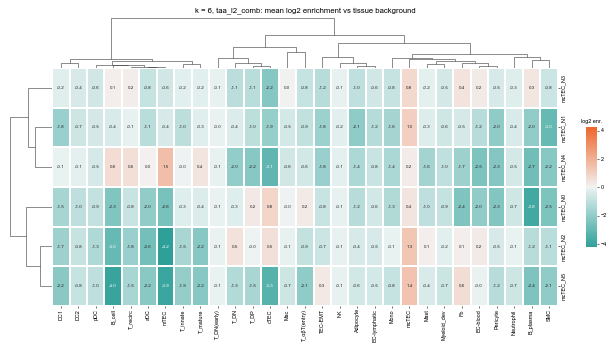

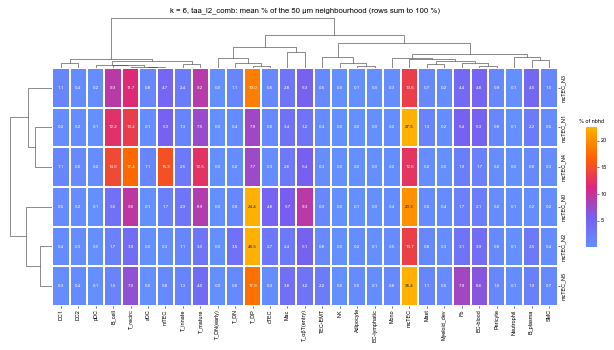

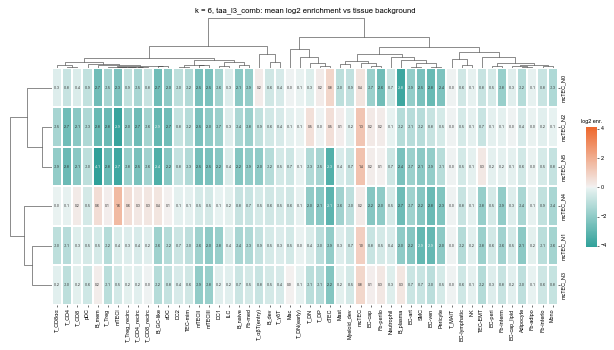

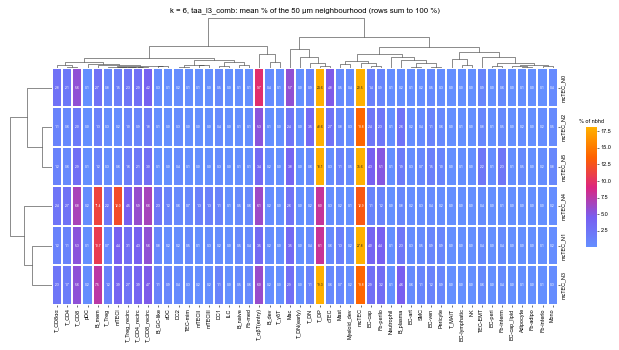

niche order: ['mcTEC_N3', 'mcTEC_N1', 'mcTEC_N4', 'mcTEC_N0', 'mcTEC_N2', 'mcTEC_N5']


In [6]:
def clustered_panels(key, annot_fs=4):
    '''Cluster once on CLUSTER_ON, then draw both views in that order.

    The enrichment scale is symmetric around 0 so depletion and enrichment are comparable; the
    proportion scale is clipped at the 2nd/98th percentile (robust=True) because T_DP at ~48 %
    would otherwise flatten every other cell type to the same blue. Printed numbers are exact.
    '''
    pct, enr = profiles[key]['pct'], profiles[key]['enr']
    vlim = np.abs(enr.values).max()
    lead_is_enr = CLUSTER_ON == 'enrichment'
    lead = enr if lead_is_enr else pct

    def _draw(mat, is_enr, linkages=None, tag=''):
        kw = dict(cmap=enr_cmap, center=0, vmin=-vlim, vmax=vlim) if is_enr else \
             dict(cmap=niche_enrich_palette, robust=True)
        if linkages is None:
            kw.update(method='average', metric='correlation')
        else:
            kw.update(row_linkage=linkages[0], col_linkage=linkages[1])
        g = sns.clustermap(mat, row_cluster=True, col_cluster=True,
                           figsize=figsize_mm(width=183, height=K * 9 + 55),
                           dendrogram_ratio=(0.08, 0.18),
                           cbar_pos=(1.02, 0.30, 0.02, 0.35),
                           annot=True, fmt='.1f', annot_kws={'fontsize': annot_fs},
                           linewidths=0.3, linecolor='white',
                           xticklabels=True, yticklabels=True, **kw)
        g.ax_heatmap.tick_params(labelsize=5)
        g.ax_heatmap.set_xlabel(''); g.ax_heatmap.set_ylabel('')
        g.ax_cbar.set_title('log2 enr.' if is_enr else '% of nbhd', fontsize=5, pad=4)
        g.ax_cbar.tick_params(labelsize=5)
        g.ax_col_dendrogram.set_title(
            f'k = {K}, {key}: ' + ('mean log2 enrichment vs tissue background' if is_enr
                                   else 'mean % of the 50 µm neighbourhood (rows sum to 100 %)'),
            fontsize=7)
        g.savefig(f'{plots_path}/recirc_niche_k{K}_{key}_{tag}_clustered.pdf', bbox_inches='tight')
        plt.show()
        return g

    g0 = _draw(lead, lead_is_enr, tag='enrichment' if lead_is_enr else 'proportion')
    links = (g0.dendrogram_row.linkage, g0.dendrogram_col.linkage)
    _draw(pct if lead_is_enr else enr, not lead_is_enr, linkages=links,
          tag='proportion' if lead_is_enr else 'enrichment')

    return {'order': ([lead.index[i] for i in g0.dendrogram_row.reordered_ind],[lead.columns[i] for i in g0.dendrogram_col.reordered_ind]), 
            'links': links}


outs = {key: clustered_panels(key, annot_fs=4 if key == 'taa_l2_comb' else 3)
          for key in CTYPE_KEYS}
orders = {key: outs[key]['order'] for key in CTYPE_KEYS}
links = {key: outs[key]['links'] for key in CTYPE_KEYS}
NICHE_ORDER = orders[CTYPE_KEY][0]      # niche order from the l2 clustering, reused below
print('niche order:', NICHE_ORDER)

In [7]:
def celltype_niche_distribution(comp, labels=labels):
    '''For each cell type, compute the proportion of cells in each niche.
    
    Returns a dataframe where rows are cell types and columns are niches,
    with values summing to 100% down each column (% of niche composed of each type).
    '''
    dnm  = comp.values.sum(1, keepdims=True)
    frac = (comp.values[sel] / dnm[sel]).astype(np.float32)
    bg   = (pd.DataFrame((comp.values[ok_all] / dnm[ok_all]).astype(np.float32), columns=comp.columns)
                .groupby(samp_all[ok_all]).mean()).loc[donor_lab].values
    Xl   = np.log2((frac + EPS) / (bg + EPS))
    
    # For each cell type, what fraction of its cells are in each niche
    # Create a matrix: rows = cell types, columns = niches
    cell_type_niche = pd.DataFrame(Xl, columns=comp.columns).groupby(labels).size()
    ct_niche_dist = pd.DataFrame(0.0, index=comp.columns, columns=NICHE_CATS)
    
    for ct in comp.columns:
        ct_mask = (pd.Series(np.arange(len(labels)), index=np.arange(len(labels)))[
            pd.Series(labels) == labels[0]].index)  # placeholder, actual logic below
        for niche in NICHE_CATS:
            niche_mask = labels == niche
            ct_niche_dist.loc[ct, niche] = (niche_mask & (frac[:, comp.columns.get_loc(ct)] > 0)).sum()
    
    ct_niche_dist = ct_niche_dist.div(ct_niche_dist.sum(axis=1), axis=0) * 100
    return ct_niche_dist

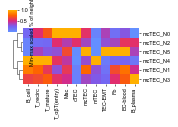

In [8]:
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import pdist

ct_levels = pd.read_excel('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/curated/thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx')

# Display relevant cell types in heatmap for paper
display_ct_l3 = ['T_DN(early)', 'T_DN', 'T_DP', 'T_αβT(entry)', 'B_dev', 'pDC']
display_ct_l2 = ['B_cell','T_recirc', 'T_mature', 'T_αβT(entry)','Mac', 'cTEC', 'mcTEC', 'mTEC', 'TEC-EMT', 'Fb', 'EC-blood', 'B_plasma']
display_ct = [c for c in ct_levels['taa_l2_v2'].unique() if c in display_ct_l2]

#plot_df = pd.concat([profiles['taa_l3_comb']['pct'].loc[:,display_ct_l3], profiles['taa_l2_comb']['pct'].loc[:,display_ct_l2]], axis=1)[display_ct]
plot_df = profiles['taa_l2_comb']['pct'].loc[:,display_ct_l2]
row_linkage = linkage(pdist(plot_df.values, metric='correlation'), method='average')
plot_df = plot_df.div(plot_df.max(axis=0), axis=1)

g = sns.clustermap(
    plot_df,
    cmap=niche_enrich_palette,
    robust=True,
    annot=False,
    row_cluster=True,
    row_linkage=links['taa_l3_comb'][0],
    dendrogram_ratio=(0.08, 0.18),
    col_cluster=False,
    fmt=".1f",
    linewidths=0,
    linecolor="white",
    cbar_kws={"label": "Min-max scaled % of neighbourhood"},
    figsize=figsize_mm(width=plot_df.shape[1] * 3+20, height=plot_df.shape[0] * 3+20),
)

g.ax_heatmap.tick_params(axis="x", labelrotation=90, labelsize=5)
g.ax_heatmap.tick_params(axis="y", labelsize=5)
row_order = plot_df.index[g.dendrogram_row.reordered_ind]

plt.savefig(f'{plots_path}/mctec_niche_k{K}_composition_pct_scaled_heatmap.pdf', bbox_inches='tight')

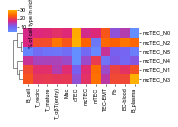

In [9]:
def celltype_niche_distribution(comp, labels=labels):
    '''For each cell type, compute the proportion of cells in each niche.
    
    Returns a dataframe where rows are cell types and columns are niches,
    with values summing to 100% down each column (% of niche composed of each type).
    '''
    dnm  = comp.values.sum(1, keepdims=True)
    frac = (comp.values[sel] / dnm[sel]).astype(np.float32)
    bg   = (pd.DataFrame((comp.values[ok_all] / dnm[ok_all]).astype(np.float32), columns=comp.columns)
                .groupby(samp_all[ok_all]).mean()).loc[donor_lab].values
    Xl   = np.log2((frac + EPS) / (bg + EPS))
    
    # For each cell type, what fraction of its cells are in each niche
    # Create a matrix: rows = cell types, columns = niches
    cell_type_niche = pd.DataFrame(Xl, columns=comp.columns).groupby(labels).size()
    ct_niche_dist = pd.DataFrame(0.0, index=comp.columns, columns=NICHE_CATS)
    
    for ct in comp.columns:
        ct_mask = (pd.Series(np.arange(len(labels)), index=np.arange(len(labels)))[
            pd.Series(labels) == labels[0]].index)  # placeholder, actual logic below
        for niche in NICHE_CATS:
            niche_mask = labels == niche
            ct_niche_dist.loc[ct, niche] = (niche_mask & (frac[:, comp.columns.get_loc(ct)] > 0)).sum()
    
    ct_niche_dist = ct_niche_dist.div(ct_niche_dist.sum(axis=1), axis=0) * 100
    return ct_niche_dist


ct_distribution_l3 = celltype_niche_distribution(comps['taa_l3_comb'], labels=labels)
ct_distribution_l2 = celltype_niche_distribution(comps['taa_l2_comb'], labels=labels)

plot_df = ct_distribution_l2.T.loc[:,display_ct_l2]

g = sns.clustermap(
    plot_df,
    cmap=niche_enrich_palette,
    robust=True,
    annot=False,
    fmt=".1f",
    row_cluster=True,
    row_linkage=links['taa_l3_comb'][0],
    col_cluster=False,
    linewidths=0,
    dendrogram_ratio=(0.08, 0.18),
    linecolor="white",
    cbar_kws={"label": "% of cell type in niche"},
    figsize=figsize_mm(width=plot_df.shape[1] * 3+20, height=plot_df.shape[0] * 3+20)
)

g.ax_heatmap.tick_params(axis="x", labelrotation=90, labelsize=5)
g.ax_heatmap.tick_params(axis="y", labelsize=5)
row_order = plot_df.index[g.dendrogram_row.reordered_ind]

plt.savefig(f'{plots_path}/mctec_niche_k{K}_celltype_distribution.pdf', bbox_inches='tight')

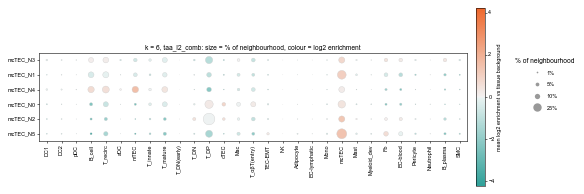

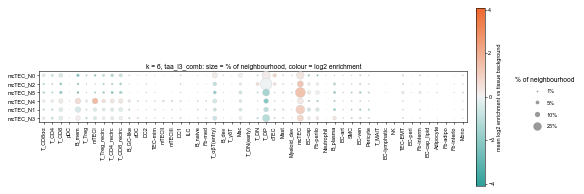

In [10]:
def dotplot_profiles(pct, enr, title, save, size_scale=110.0):
    '''Dot size = % of the neighbourhood, dot colour = mean log2 enrichment.

    Same encoding as plotting.niche_abundance.plot_niche_ctype_dotplot, which cannot be used here
    because this composition is a neighbourhood mean rather than a crosstab of obs.
    '''
    from matplotlib.colors import Normalize
    from matplotlib.lines import Line2D

    nY, nX = pct.shape
    Xg, Yg = np.meshgrid(np.arange(nX), np.arange(nY))
    vmax = np.abs(enr.values).max()
    sref = pct.values.max()

    fig, ax = plt.subplots(figsize=figsize_mm(width=183, height=nY * 9 + 35))
    sc = ax.scatter(Xg.ravel(), Yg.ravel(), s=(pct.values / sref * size_scale).ravel(),
                    c=enr.values.ravel(), cmap=enr_cmap, norm=Normalize(-vmax, vmax),
                    edgecolors='0.8', linewidths=0.3, zorder=3)
    ax.set_xticks(np.arange(nX)); ax.set_xticklabels(pct.columns, rotation=90, fontsize=5)
    ax.set_yticks(np.arange(nY)); ax.set_yticklabels(pct.index, fontsize=5)
    ax.set_xlim(-0.5, nX - 0.5); ax.set_ylim(-0.5, nY - 0.5)
    ax.invert_yaxis(); ax.set_aspect('equal'); ax.grid(False); ax.set_title(title)

    cbar = fig.colorbar(sc, ax=ax, fraction=0.02, pad=0.02)
    cbar.set_label('mean log2 enrichment vs tissue background')
    svals = [v for v in (1, 5, 10, 25, 50) if v <= sref]
    ax.legend(handles=[Line2D([], [], marker='o', linestyle='', markerfacecolor='0.6',
                              markeredgecolor='none',
                              markersize=np.sqrt(v / sref * size_scale), label=f'{v}%')
                       for v in svals],
              title='% of neighbourhood', bbox_to_anchor=(1.10, 1), loc='upper left',
              frameon=False, labelspacing=1.2)
    fig.savefig(save, bbox_inches='tight')
    plt.show()


for key in CTYPE_KEYS:
    order_r, order_c = orders[key]
    dotplot_profiles(profiles[key]['pct'].loc[order_r, order_c],
                     profiles[key]['enr'].loc[order_r, order_c],
                     title=f'k = {K}, {key}: size = % of neighbourhood, colour = log2 enrichment',
                     save=f'{plots_path}/mctec_niche_k{K}_{key}_dotplot.pdf')

## 7 · Niche × morphology

Where the niches sit in the tissue, three ways. Morphology keeps its anatomical order (cortex →
medulla → adipose → fibrosis → vessel) rather than being clustered; the niches keep the order from
section 6 so every panel in the notebook matches.

- **proportion** — `plot_niche_ctype_abundance(normalize="niche", standard_scale=None)`. The
  `standard_scale=None` matters: the module's default of 1 rescales each column to [0, 1] and would
  destroy the fractions.
- **log2 O/E with significance** — `plot_niche_ctype_enrichment`, i.e. LM's
  `thyAging_morphoFM_patch_*_log2oe_clustermap.pdf` restored: per-donor observed/expected,
  one-sample t-test across the 7 donors, FDR-BH, stars.
- **dotplot** — size = fraction of the niche, colour = log2 O/E, edge = FDR-significant direction.

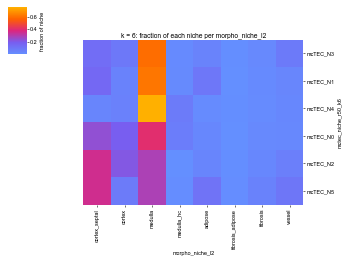

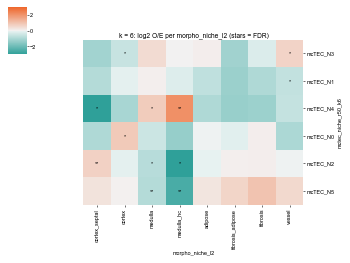

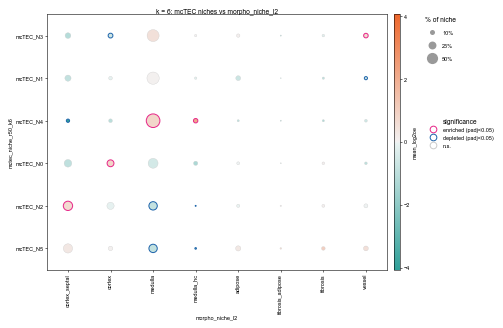

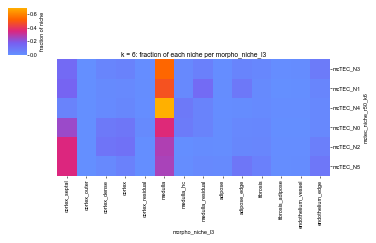

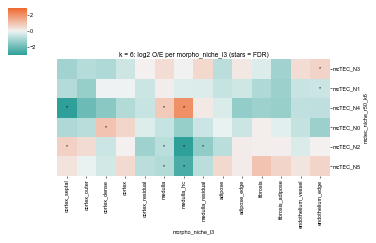

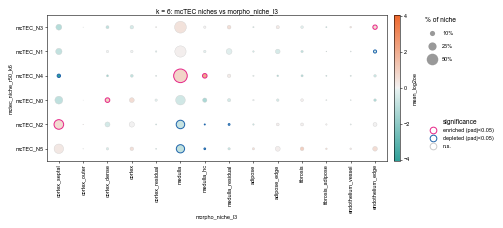

In [11]:
MORPHO_ORDERS = {
    'morpho_niche_l2': ['cortex_septal', 'cortex', 'medulla', 'medulla_hc',
                        'adipose', 'fibrosis_adipose', 'fibrosis', 'vessel'],
    'morpho_niche_l3': ['cortex_septal', 'cortex_outer', 'cortex_dense', 'cortex', 'cortex_residual',
                        'medulla', 'medulla_hc', 'medulla_residual', 'adipose', 'adipose_edge',
                        'fibrosis', 'fibrosis_adipose', 'endothelium_vessel', 'endothelium_edge'],
}

mct = xenium_adata[xenium_adata.obs[NICHE_KEY].notna()]      # non-mcTEC carry a NaN niche label

for lvl, order in MORPHO_ORDERS.items():
    plot_niche_ctype_abundance(
        mct, niche_key=NICHE_KEY, ctype_key=lvl, niche_order=NICHE_ORDER, celltypes=order,
        normalize='niche', standard_scale=None, cmap=niche_enrich_palette,
        figsize=figsize_mm(width=120, height=K * 8 + 35),
        title=f'k = {K}: fraction of each niche per {lvl}',
        cbar_kws={'label': 'fraction of niche'},
        save=f'{plots_path}/mctec_niche_k{K}_{lvl}_fraction.pdf')

    plot_niche_ctype_enrichment(
        mct, niche_key=NICHE_KEY, ctype_key=lvl, donor_key='donor',
        niche_order=NICHE_ORDER, celltypes=order, cmap=enr_cmap, vmax=3,
        figsize=figsize_mm(width=120, height=K * 8 + 35),
        title=f'k = {K}: log2 O/E per {lvl} (stars = FDR)',
        save=f'{plots_path}/mctec_niche_k{K}_{lvl}_log2oe.pdf')

    plot_niche_ctype_dotplot(
        mct, niche_key=NICHE_KEY, ctype_key=lvl, donor_key='donor',
        niche_order=NICHE_ORDER, celltypes=order, size_norm='niche', cmap=enr_cmap,
        figsize=figsize_mm(width=140, height=K * 10 + 45),
        title=f'k = {K}: mcTEC niches vs {lvl}',
        save=f'{plots_path}/mctec_niche_k{K}_{lvl}_dotplot.pdf')

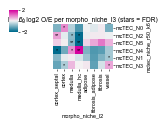

In [12]:
plot_niche_ctype_enrichment(
        mct, niche_key=NICHE_KEY, ctype_key='morpho_niche_l2', donor_key='donor',
        niche_order=row_order, celltypes=MORPHO_ORDERS['morpho_niche_l2'], cmap=create_diverging_palette(thyAgeing_colors['blue'], thyAgeing_colors['magenta'], s=150, l=40, as_cmap=True), vmax=2,
        figsize=figsize_mm(width=plot_df.shape[1] * 3+20, height=plot_df.shape[0] * 3+20),
        title=f'k = {K}: log2 O/E per {lvl} (stars = FDR)',
        save=f'{plots_path}/mctec_niche_k{K}_morpho_niche_l2_log2oe_pub.pdf'
        )

## 8 · Niche frequency per donor and age group

The age readout: what fraction of a donor's mcTEC sits in each niche, donors ordered youngest to
oldest. With 7 donors in 3 groups this is descriptive — read the per-donor bars, not a p-value.
The second table is the reverse view, which donors each niche is *made of*; the two answer different
questions, because mcTEC counts per donor are very unequal (A72 alone contributes ~40 %).

In [18]:
NICHE_COLORS

['#648FFF', '#DC267F', '#FE6100', '#FFB000', '#18868F', '#785EF0']

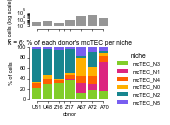

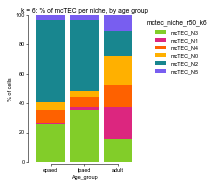

col_0,mcTEC_N3,mcTEC_N1,mcTEC_N4,mcTEC_N0,mcTEC_N2,mcTEC_N5
row_0,,,,,,
U51,21.800000,0.300000,9.200000,1.900000,63.200000,3.600000
U48,28.900000,0.500000,9.100000,7.700000,50.200000,3.600000
Z16,31.000000,0.400000,5.500000,2.600000,56.400000,4.100000
Z17,36.500000,2.200000,7.300000,4.900000,45.600000,3.400000
A67,12.100000,20.000000,13.200000,33.700000,4.400000,16.600000
A72,18.100000,10.600000,17.000000,16.000000,29.000000,9.200000
A70,15.000000,56.600000,11.300000,6.300000,4.900000,5.900000


col_0,U51,U48,Z16,Z17,A67,A72,A70
row_0,,,,,,,
mcTEC_N3,4.600000,8.800000,3.600000,16.500000,16.800000,38.200000,11.300000
mcTEC_N1,0.100000,0.200000,0.000000,1.100000,29.600000,23.700000,45.300000
mcTEC_N4,2.700000,3.900000,0.900000,4.600000,25.800000,50.200000,12.000000
mcTEC_N0,0.400000,2.600000,0.300000,2.400000,51.700000,37.300000,5.200000
mcTEC_N2,10.500000,12.100000,5.200000,16.200000,4.800000,48.300000,2.900000
mcTEC_N5,1.500000,2.100000,0.900000,3.000000,45.400000,38.200000,8.800000


In [21]:
#from plotting.niche_abundance import plot_composition_barplot
NICHE_COLORS = [thyAgeing_colors[c] for c in ['grass', 'magenta', 'orange', 'yellow', 'teal', 'purple', 'mint']]
NICHE_PAL = [NICHE_COLORS[n] for n in range(len(NICHE_ORDER))]
fig, axes = plt.subplots(2, 1, figsize=figsize_mm(width=55, height=40), gridspec_kw={'height_ratios': [1, 4]}, sharex = True)

# Top panel: number of cells per donor
donor_counts = mct.obs['donor'].value_counts().reindex(DONOR_ORDER)
sns.barplot(
    x=donor_counts.index, y=donor_counts.values, ax=axes[0],
    color=thyAgeing_greys['grey3'], linewidth=0, edgecolor='black',
    width = 0.85,
)

axes[0].set_yscale('log')
axes[0].set_xlabel('')
axes[0].set_xticklabels([])
axes[0].set_ylabel('n cells (log scale)', fontsize=5)
axes[0].tick_params(axis='y', labelsize=5)
sns.despine(ax=axes[0], offset=(0, 2), trim=True)

# Bottom panel: composition barplot
plot_composition_barplot(
    mct, sample_key='donor', annotation=NICHE_KEY, samples=DONOR_ORDER, order=NICHE_ORDER,
    colors=NICHE_PAL,
    figsize=figsize_mm(width=60, height=50),
    legend_kwargs={'title' : 'niche'},
    title=f"k = {K}: % of each donor's mcTEC per niche",
    save=f'{plots_path}/mctec_niche_k{K}_per_donor.pdf', 
    linewidth=0,
    ax=axes[1])
#plt.savefig(f'{plots_path}/recirc_niche_k{K}_per_donor.pdf', dpi =300, bbox_inches='tight')

plot_composition_barplot(
    mct, sample_key='Age_group', annotation=NICHE_KEY, samples=['epaed', 'lpaed', 'adult'],
    order=NICHE_ORDER, colors=NICHE_PAL,
    figsize=figsize_mm(width=70, height=60),
    title=f'k = {K}: % of mcTEC per niche, by age group',
    save=f'{plots_path}/recirc_niche_k{K}_per_agegroup.pdf')

rep = pd.crosstab(donor_lab, labels, normalize='index').reindex(DONOR_ORDER)[NICHE_ORDER] * 100
of_niche = pd.crosstab(labels, donor_lab, normalize='index').loc[NICHE_ORDER, DONOR_ORDER] * 100
rep.round(2).to_csv(f'{results_path}/recirc_niche_k{K}_per_donor_pct.csv')
of_niche.round(2).to_csv(f'{results_path}/recirc_niche_k{K}_donor_composition_pct.csv')

display(rep.round(1).style.background_gradient(cmap='Blues', axis=None)
           .set_caption("% of each donor's mcTEC per niche (rows sum to 100)"))
display(of_niche.round(1).style.background_gradient(cmap='Blues', axis=None)
           .set_caption('% of each niche coming from each donor (rows sum to 100)'))

## 9 · Niches on tissue

All seven sections, grey = every other cell.

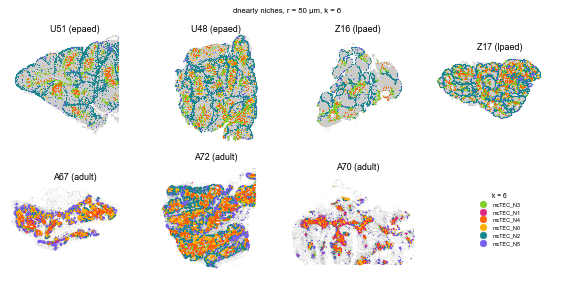

In [20]:
fig, axes = plt.subplots(2, 4, figsize=figsize_mm(width=183, height=90)) #figsize=figsize_mm(width=183, height=90)
for ax, s in zip(axes.ravel(), DONOR_ORDER):
    m   = (xenium_adata.obs['sample_ID'].astype(str) == s).values
    xy  = xenium_adata.obsm['spatial'][m]
    lab = xenium_adata.obs[NICHE_KEY].values[m]
    ax.scatter(xy[:, 0], xy[:, 1], s=0.05, c=thyAgeing_greys['grey2'], lw=0, rasterized=True)
    for n, colr in zip(NICHE_ORDER, NICHE_PAL):
        hit = np.asarray(lab == n)
        ax.scatter(xy[hit, 0], xy[hit, 1], s=1, c=colr, lw=0, rasterized=True)
    ax.set_title(f'{s} ({AGE_GROUP[s]})', fontsize=8)
    ax.set_aspect('equal'); ax.invert_yaxis(); ax.axis('off')
axes.ravel()[-1].axis('off')
axes.ravel()[-1].legend(
    handles=[plt.Line2D([], [], marker='o', linestyle='', markersize=6, color=c, label=n)
             for n, c in zip(NICHE_ORDER, NICHE_PAL)],
    loc='center', frameon=False, title=f'k = {K}')
fig.suptitle(f'dnearly niches, r = {R_NICHE} µm, k = {K}')
fig.tight_layout()
fig.savefig(f'{plots_path}/Xenium_mctec_niche_k{K}_sections.png', dpi=300, bbox_inches='tight')
plt.show()

## 10 · Is k = 6 sound?

Four checks, all on this partition. The first is LM's: recompute each niche's profile *within each
donor* and correlate it against the global profile — measured in enrichment space, because scoring
raw fractions compares donors on the very composition shift that was normalised out before
clustering, and then every niche fails regardless of k.

The other three ask whether six niches are too many: **stability** (refit on 10 independent 80 %
subsamples, ARI between runs on shared cells), **leave-one-donor-out** (refit without each donor,
re-assign every cell, how much of each niche still lands in one cluster) and **redundancy**
(pairwise correlation of the profiles; a pair above ~0.95 is a split without a difference).

In [32]:
from itertools import combinations

n_donors = len(np.unique(donor_lab))
enr_df   = pd.DataFrame(profiles[CTYPE_KEY]['X'], columns=comp.columns)
enr_full = pd.DataFrame(profiles[CTYPE_KEY]['X'], columns=comp.columns).groupby(labels).mean()

# (a) per-donor profile consistency ------------------------------------------
by_dn  = enr_df.groupby([labels, donor_lab]).mean()
n_cell = pd.Series(labels).groupby([labels, donor_lab]).size()
cons = pd.DataFrame({
    n: {d: np.corrcoef(by_dn.loc[(n, d)].values, enr_full.loc[n].values)[0, 1]
        for d in by_dn.loc[n].index if n_cell.loc[(n, d)] >= MIN_CELLS}
    for n in NICHE_CATS})

# (b) stability under subsampling --------------------------------------------
rng_s, runs = np.random.default_rng(SEED), []
for r in range(10):
    idx = rng_s.choice(len(pcs), int(0.8 * len(pcs)), replace=False)
    lab_r = np.full(len(pcs), -1)
    lab_r[idx] = MiniBatchKMeans(n_clusters=K, random_state=SEED + r, n_init=10,
                                 batch_size=4096).fit_predict(pcs[idx])
    runs.append(lab_r)
aris = [adjusted_rand_score(a[(a >= 0) & (b >= 0)], b[(a >= 0) & (b >= 0)])
        for a, b in combinations(runs, 2)]

# (c) leave-one-donor-out ------------------------------------------------------
lodo = {}
for d in DONOR_ORDER:
    km_d = MiniBatchKMeans(n_clusters=K, random_state=SEED, n_init=10,
                           batch_size=4096).fit(pcs[donor_lab != d])
    lodo[d] = pd.crosstab(labels, km_d.predict(pcs), normalize='index').max(axis=1)
lodo = pd.DataFrame(lodo)[DONOR_ORDER].loc[NICHE_ORDER]

# (d) redundancy ---------------------------------------------------------------
prof_r = enr_full.T.corr()
np.fill_diagonal(prof_r.values, np.nan)

summary = pd.DataFrame({
    'n_cells':          pd.Series(labels).value_counts(),
    'n_donors_>=1%':    (rep >= 1).sum(),
    'n_donors_scored':  cons.notna().sum(),
    'min_donor_r':      cons.min(),
    'median_donor_r':   cons.median(),
    'LODO_recovery_min': lodo.min(axis=1),
    'max_r_to_another_niche': prof_r.max(),
}).loc[NICHE_ORDER]
summary.round(3).to_csv(f'{results_path}/mctec_niche_k{K}_validation.csv')
lodo.round(3).to_csv(f'{results_path}/mctec_niche_k{K}_lodo_recovery.csv')

print(f'stability ARI across 10 refits: mean {np.mean(aris):.3f}, worst pair {np.min(aris):.3f}')
print(f'most similar pair of niches: r = {np.nanmax(prof_r.values):.3f}')
display(summary.round(3))
display(cons.round(2).style.background_gradient(cmap='RdYlGn', vmin=0.4, vmax=1.0)
            .set_caption(f'per-donor profile correlation (NaN = <{MIN_CELLS} cells)'))
display(lodo.round(2).style.background_gradient(cmap='RdYlGn', vmin=0.4, vmax=1.0)
            .set_caption('niche recovery when each donor is left out'))

stability ARI across 10 refits: mean 0.421, worst pair 0.260
most similar pair of niches: r = 0.725


,n_cells,n_donors_>=1%,n_donors_scored,min_donor_r,median_donor_r,LODO_recovery_min,max_r_to_another_niche
mcTEC_N3,24794,7,7,0.623,0.845,0.480,0.499
mcTEC_N1,23345,4,5,0.496,0.893,0.348,0.598
mcTEC_N4,17758,7,7,0.800,0.833,0.574,0.598
mcTEC_N0,22532,7,7,0.487,0.815,0.479,0.477
mcTEC_N2,31492,7,7,0.733,0.959,0.463,0.725
mcTEC_N5,12654,7,7,0.786,0.862,0.474,0.725


,mcTEC_N0,mcTEC_N1,mcTEC_N2,mcTEC_N3,mcTEC_N4,mcTEC_N5
A67,0.980000,0.890000,0.880000,0.880000,0.940000,0.970000
A70,0.790000,0.930000,0.730000,0.620000,0.820000,0.810000
A72,0.970000,0.940000,0.980000,0.960000,0.990000,0.970000
U48,0.680000,0.500000,0.960000,0.810000,0.830000,0.860000
U51,0.490000,nan,0.910000,0.770000,0.810000,0.790000
Z16,0.820000,nan,0.980000,0.850000,0.800000,0.870000
Z17,0.890000,0.760000,0.970000,0.900000,0.850000,0.860000


,U51,U48,Z16,Z17,A67,A72,A70
row_0,,,,,,,
mcTEC_N3,0.690000,0.750000,0.730000,0.830000,0.480000,0.540000,0.810000
mcTEC_N1,0.810000,0.490000,0.550000,0.730000,0.470000,0.530000,0.350000
mcTEC_N4,0.940000,0.950000,0.690000,0.730000,0.570000,0.720000,0.910000
mcTEC_N0,0.920000,0.730000,0.770000,0.810000,0.480000,0.890000,0.700000
mcTEC_N2,0.640000,0.580000,0.820000,0.740000,0.540000,0.740000,0.460000
mcTEC_N5,0.680000,0.800000,0.850000,0.540000,0.470000,0.770000,0.490000


## 11 · Saved outputs

In [33]:
print('tables ->', results_path)
for f in sorted(os.listdir(results_path)):
    print('  ', f)
print('\nfigures ->', plots_path)
for f in sorted(os.listdir(plots_path)):
    print('  ', f)

tables -> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/morpho_niches/mctecNiche
   mctec_niche_k6_donor_composition_pct.csv
   mctec_niche_k6_lodo_recovery.csv
   mctec_niche_k6_per_donor_pct.csv
   mctec_niche_k6_taa_l2_comb_composition_pct.csv
   mctec_niche_k6_taa_l2_comb_log2enrichment.csv
   mctec_niche_k6_taa_l3_comb_composition_pct.csv
   mctec_niche_k6_taa_l3_comb_log2enrichment.csv
   mctec_niche_k6_validation.csv
   mctec_niche_labels_r50_k6.csv

figures -> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/mctecNiche
   Xenium_mctec_niche_k6_sections.png
   mctec_niche_k6_celltype_distribution.pdf
   mctec_niche_k6_composition_pct_scaled_heatmap.pdf
   mctec_niche_k6_morpho_niche_l2_dotplot.pdf
   mctec_niche_k6_morpho_niche_l2_fraction.pdf
   mctec_niche_k6_morpho_niche_l2_log2oe.pdf
   mctec_niche_k6_morpho_niche_l2_log2oe_pub.pdf
   mctec_niche_k6_morpho_niche_l2_log2oe_pub_swapped.pdf
   mctec_niche_k6_morpho_niche_